# Chapter 3 · Geometry and distortion

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** [Chapter 2](02-classical-image-processing.ipynb) (filters) and matrices as maps
(book 1).
**You will:** move an image with a matrix, undo a phone's perspective with a homography, and
put a number on blur -- then meet the five photo qualities the challenge is measured along.

A phone photo of a document differs from a scan in three ways: the paper is seen at an angle,
the light is uneven, and the camera is a little out of focus. Each has a model.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()
bill = qb.generate_bills(1, seed=3)[0]
img = qb.render(bill)
h, w = img.shape[:2]

## Affine: rotate, scale, shift

In homogeneous coordinates a point is $(x, y, 1)$, and every rotation, scaling and shift is one
2 x 3 matrix. OpenCV builds the rotation about a centre for us; applying it is one call.

In [2]:
rot = cv2.getRotationMatrix2D((w / 2, h / 2), 8, 1.0)
print(np.round(rot, 3))
rotated = cv2.warpAffine(img, rot, (w, h), borderValue=(235, 235, 235))

[[  0.99    0.139 -37.11 ]
 [ -0.139   0.99   89.304]]


## Perspective: the homography

A camera looking at a flat sheet at an angle maps the sheet's rectangle to a general
quadrilateral. That map is a **homography**, a 3 x 3 matrix $H$ with

$$\begin{pmatrix} x' \\ y' \\ 1 \end{pmatrix} \sim H \begin{pmatrix} x \\ y \\ 1 \end{pmatrix}$$

up to scale: eight unknowns, so four point pairs determine it. Given the four corners of the
sheet in the photo, we can map it back.

mean error after rectifying, grey levels: 4.3


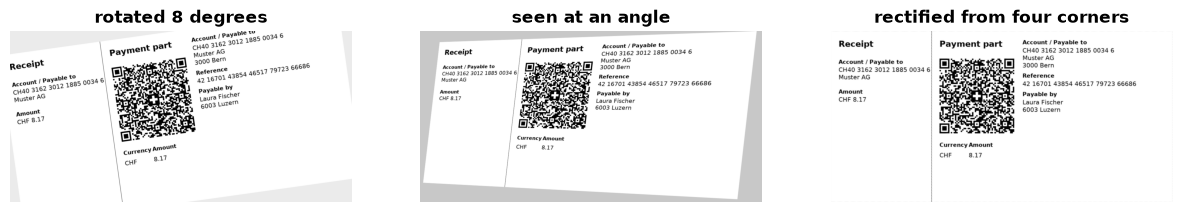

In [3]:
src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
seen = np.float32([[70, 40], [w - 20, 0], [w - 90, h - 10], [10, h - 70]])
H = cv2.getPerspectiveTransform(src, seen)
photo = cv2.warpPerspective(img, H, (w, h), borderValue=(200, 200, 200))
H_back = cv2.getPerspectiveTransform(seen, src)
rectified = cv2.warpPerspective(photo, H_back, (w, h))
fig, axes = plt.subplots(1, 3, figsize=(15, 2.8))
for ax, im, title in zip(axes, [rotated, photo, rectified], ["rotated 8 degrees", "seen at an angle",
                                                             "rectified from four corners"], strict=True):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
inner = (slice(80, h - 80), slice(80, w - 80))
print("mean error after rectifying, grey levels:",
      np.abs(rectified[inner].astype(float) - img[inner].astype(float)).mean().round(1))

The small remaining error is interpolation: the warp moved pixels to fractional positions and
back. In practice the four corners come from a detector (chapter 4); here we knew them.

## Measuring blur

A sharp image has strong second derivatives at every edge; blur smooths them away. The
**variance of the Laplacian** turns that into one number -- a classic, cheap focus measure.

In [4]:
def sharpness(image):
    grey = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) if image.ndim == 3 else image
    return float(cv2.Laplacian(grey, cv2.CV_64F).var())

for sigma in (0, 1, 2, 3, 4):
    blurred = img if sigma == 0 else cv2.GaussianBlur(img, (0, 0), sigma)
    print(f"Gaussian blur sigma {sigma}: sharpness {sharpness(blurred):9.0f}")

Gaussian blur sigma 0: sharpness      5182
Gaussian blur sigma 1: sharpness       337
Gaussian blur sigma 2: sharpness        39
Gaussian blur sigma 3: sharpness         7
Gaussian blur sigma 4: sharpness         2


## The five photo qualities

`qrbills.distort` combines everything above, growing with the level: rotation, perspective,
light that falls off to one side, blur and sensor noise, then a smaller image and JPEG
compression. These five levels are the x-axis of the challenge.

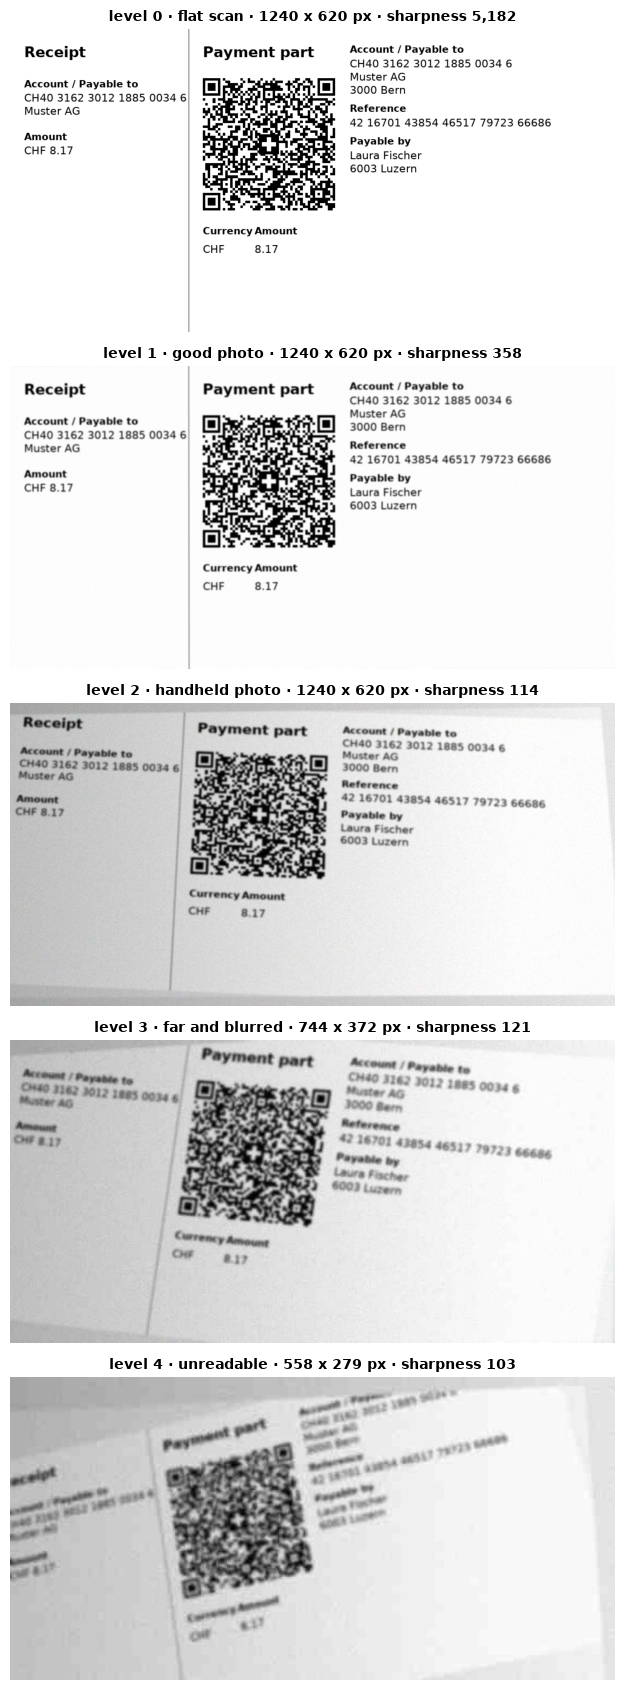

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(9, 17))
for level, ax in enumerate(axes):
    photo = qb.distort(img, level, seed=level)
    ax.imshow(photo)
    ax.set_title(f"level {level} · {qb.QUALITY_LEVELS[level]} · {photo.shape[1]} x {photo.shape[0]} px · "
                 f"sharpness {sharpness(photo):,.0f}", fontsize=10)
    ax.axis("off")
fig.tight_layout()

The sharpness falls by orders of magnitude across the levels. Chapter 5 asks whether a network
can tell the levels apart better than this one number can.

## What to remember

- Rotation, scaling and shifts are one affine matrix; perspective is a homography.
- Four point pairs fix a homography, so four found corners are enough to rectify a page.
- Blur can be measured: the variance of the Laplacian.

## Exercises

1. Apply `H` and then `H_back` to the four corners with `cv2.perspectiveTransform`. Exactly back?
2. Make the light gradient run top to bottom. Which chapter-2 threshold still works?
3. Plot sharpness against the blur sigma on a log axis. What shape is it?

**Next:** [Chapter 4 · Detection](04-detection.ipynb)